In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [77]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [78]:
def grad(activations, weights, biases, inputs, outputs):
    
    grad_activation = [0*act for act in activations]
    grad_bias = [0*bias for bias in biases]
    grad_weight = [0*weight for weight in weights]
    
    for k in range(len(biases[-2])):
        grad_activation[-2][k] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * weights[-1][j][k] for j in range(len(outputs))])

    for i in range(len(biases[-3])):
        grad_activation[-3][i] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * weights[-2][k][i] for k in range(len(biases[-2]))]) for j in range(len(outputs))])

    for m in range(len(biases[-4])):
        grad_activation[-4][m] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * sum([weights[-2][k][i] * sigma_der(np.dot(weights[-3][i], activations[-4]) + 
                                    biases[-3][i]) * weights[-3][i][m] for i in range(len(biases[-3]))]) for k in range(len(biases[-2]))]) 
                                      for j in range(len(outputs))])
        
    
    for j in range(len(outputs)):
        grad_bias[-1][j] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                biases[-1][j])

    for k in range(len(biases[-2])):
        grad_bias[-2][k] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k])
    
    for k in range(len(biases[-3])):
        grad_bias[-3][k] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k])

    for k in range(len(biases[-4])):
        grad_bias[-4][k] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k])

    
    
    
    for j in range(len(outputs)):
        for k in range(len(biases[-2])):
            grad_weight[-1][j][k] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * activations[-2][k]

    for k in range(len(biases[-2])):
        for i in range(len(biases[-3])):
            grad_weight[-2][k][i] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k]) * activations[-3][i]

    for k in range(len(biases[-3])):
        for i in range(len(biases[-4])):
            grad_weight[-3][k][i] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k]) * activations[-4][i]

    for k in range(len(biases[-4])):
        for i in range(len(inputs)):
            grad_weight[-4][k][i] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k]) * inputs[i]
            
    
    return grad_activation, grad_weight, grad_bias

In [79]:
def neural_network(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations):

    biases = []

    for i in range(number_hidden_layers):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs)))

    weights = []

    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs))))

    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs), nodes_hidden_layers[-1])))

    cost = []

    for k in range(iterations):
        
        activations = det_activations(inputs, weights, biases)
    
        cost.append(sum([(activations[-1].tolist()[i] - outputs[i])**2 for i in range(len(outputs))]))
    
        gr_act, gr_w, gr_b = grad(activations, weights, biases, inputs, outputs)
    
        weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
        biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

    return activations, weights, biases, cost

In [80]:
inputs = np.random.rand(20)
outputs = [1, 0.3, 0.2, 0.5, 0.6]

activations, weights, biases, cost = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 30) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

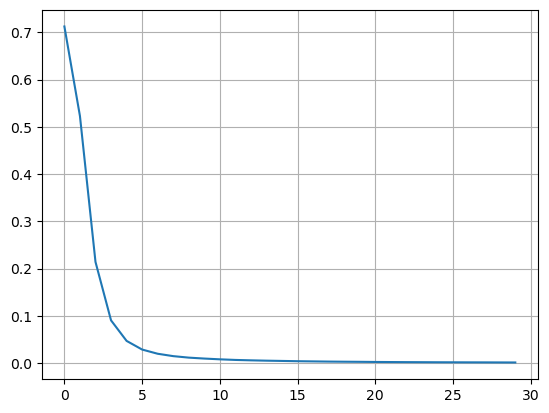

In [81]:
plt.plot(cost);
plt.grid();